# 5% 600K PEG — Per-cell $K$, $n$ (standard: Production @ $h_0$)

**Platform goal.** Characterize **each cell independently** for non-Newtonian $(K,n)$. Methods that need an average $n$ or a calibration bank from other samples are out of scope.

**Standard.** Manual GT and live production both evaluate stress at the detected hitpoint $h_0$ (not an offset). Auto production path: `predict_cell_rheology` → $\tau$ at $h_{\mathrm{norm}}=0$.

**One-sentence takeaway.** On this PEG, **$n$ is already near the 10% band per cell**; **$K$ is limited by hit/gap geometry**. Geometric floor from manual $\pm 0.01\,\mathrm{mm}$ around $h_0$ sets the unavoidable best-case error.

## 1. Setup & load

In [1]:
from __future__ import annotations

import io
import sys
from pathlib import Path
from typing import Any, Dict, List, Optional, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import curve_fit

NOTEBOOK_DIR = Path.cwd().resolve()
ROOT = None
for candidate in [NOTEBOOK_DIR, NOTEBOOK_DIR.parent, NOTEBOOK_DIR.parent.parent]:
    if (candidate / "src" / "viscometry").is_dir():
        ROOT = candidate
        break
if ROOT is None:
    raise RuntimeError("Could not locate repo root (src/viscometry)")
sys.path.insert(0, str(ROOT / "src"))

from viscometry.measurement.feedback import RotationalDragFeedbackController
from viscometry.measurement.hitpoint import (
    extract_hitpoint_from_sequence,
    extract_vote_last_clean_from_sequence,
)
from viscometry.rheology.constants import PCT_TO_PA
from viscometry.rheology.live_adapter import filter_measurement_points, predict_cell_rheology
from viscometry.rheology.prediction import shear_rate
from viscometry.rheology.stress_powerlaw import fit_stress_powerlaw

MANUAL_CSV = ROOT / "results" / "auto_runs" / "5%600KPEG_MANUAL_RAW.csv"
AUTO_CSV = ROOT / "results" / "auto_runs" / "5%600K_PEG_reproducibility_20261119.csv"

MANUAL_INC_MM = 0.013
HIT_FLOOR_MM = 0.01   # geometric standard: +/- this about h0
G_REF = 20.0
TARGET_PCT = 10.0

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
print(f"ROOT={ROOT}")
print(f"Manual step={MANUAL_INC_MM*1e3:.0f} um | geometric floor +/-{HIT_FLOOR_MM*1e3:.0f} um about h0")
print("Standard: Production / GT at h0 (detected hitpoint)")

ROOT=/Users/ianng/Documents/GitHub/Automated_Viscometry
Manual step=13 um | geometric floor +/-10 um about h0
Standard: Production / GT at h0 (detected hitpoint)


In [2]:
def load_manual(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path)
    df["Formulation"] = df["Formulation"].ffill()
    for col in ["Increment", "speed_RPM", "SR_1/s", "Viscosity_cP", "Torque_%", "SS_dyne/cm2", "Accuracy_cP"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    missing = df["SS_dyne/cm2"].isna()
    df.loc[missing, "SS_dyne/cm2"] = df.loc[missing, "Viscosity_cP"] * df.loc[missing, "SR_1/s"] / 100.0
    df["tau_Pa"] = df["SS_dyne/cm2"] / 10.0
    df["gamma_dot_1_s"] = df["SR_1/s"]
    df["drag"] = df["Torque_%"] / df["speed_RPM"]
    df["z_synth_mm"] = df["Increment"].astype(float) * MANUAL_INC_MM
    return df


def _parse_auto_blocks(path: Path) -> List[Tuple[str, pd.DataFrame]]:
    if not path.exists():
        return []
    raw = pd.read_csv(path, header=None)
    blocks: List[Tuple[str, pd.DataFrame]] = []
    i = 0
    while i < len(raw):
        cell0 = str(raw.iloc[i, 0])
        if cell0.startswith("# Timestamp"):
            name = cell0.replace("# Timestamp:", "").strip()
            hdr = [str(x) for x in raw.iloc[i + 1].tolist()]
            j = i + 2
            rows = []
            while j < len(raw) and not str(raw.iloc[j, 0]).startswith("# Timestamp"):
                rows.append(raw.iloc[j].tolist())
                j += 1
            df = pd.DataFrame(rows, columns=hdr)
            for c in ["cell", "Z_Height_mm", "RPM", "Elapsed_Time_s", "Torque_%", "Rotational_Drag"]:
                if c in df.columns:
                    df[c] = pd.to_numeric(df[c], errors="coerce")
            blocks.append((name, df))
            i = j
        else:
            i += 1
    return blocks


def _block_fingerprint(df: pd.DataFrame) -> str:
    """Stable content hash so identical pasted blocks are kept once."""
    cols = [c for c in ["cell", "Z_Height_mm", "RPM", "Torque_%", "Rotational_Drag"] if c in df.columns]
    if not cols:
        return f"empty:{len(df)}"
    payload = df.loc[:, cols].astype(str).to_csv(index=False)
    return payload


def load_auto_experiments(*paths: Path) -> List[Dict[str, Any]]:
    """Load every cell from every run block; unique short labels by run date."""
    exps: List[Dict[str, Any]] = []
    seen_blocks: set = set()
    run_dates: List[str] = []
    date_to_day: Dict[str, int] = {}

    for path in paths:
        for name, df in _parse_auto_blocks(path):
            if df.empty or "cell" not in df.columns:
                continue
            fp = _block_fingerprint(df)
            if fp in seen_blocks:
                continue
            seen_blocks.add(fp)

            # Timestamp names look like 20261126_153936 — group by calendar day.
            run_date = str(name).strip().split("_")[0]
            if run_date not in date_to_day:
                date_to_day[run_date] = len(date_to_day) + 1
                run_dates.append(run_date)
            day_idx = date_to_day[run_date]

            df = df.dropna(subset=["cell"]).copy()
            if df.empty:
                continue
            for cid, g in df.groupby(df["cell"].astype(int)):
                cid = int(cid)
                short = f"c{cid}" if day_idx == 1 else f"c{cid}_d{day_idx}"
                exps.append({
                    "name": f"{name}_cell{cid}",
                    "short": short,
                    "cell": cid,
                    "run_date": run_date,
                    "day_idx": day_idx,
                    "df": g.reset_index(drop=True),
                })
    return exps


def _beneath_hit_z(df: pd.DataFrame) -> float:
    if "Confirm_hit" in df.columns:
        conf = df[df["Confirm_hit"].astype(str).str.upper().eq("HIT")]
        if len(conf):
            return float(conf["Z_Height_mm"].min())
    if "Hit_Detected" in df.columns:
        hits = df[df["Hit_Detected"].astype(str).str.upper().eq("TRUE")]
        if len(hits):
            return float(hits["Z_Height_mm"].min())
    return float(df["Z_Height_mm"].min())


def hit_z_from_flags(df: pd.DataFrame) -> float:
    # Auto h0 = Z just above Confirm_hit (beneath-contact marker).
    zs = np.sort(np.unique(df["Z_Height_mm"].to_numpy(dtype=float)))
    zs = zs[np.isfinite(zs)]
    beneath = _beneath_hit_z(df)
    above = zs[zs > beneath + 1e-9]
    if len(above):
        return float(above.min())
    return float(beneath)


manual = load_manual(MANUAL_CSV)
exps = load_auto_experiments(AUTO_CSV)
print(f"Manual rows={len(manual)} incs={manual['Increment'].nunique()}")
print(f"Auto experiments={len(exps)} (all cells across all run days)")
for e in exps:
    d = e["df"]
    print(
        f"  {e['short']:8s} day={e.get('day_idx', 1)} ({e.get('run_date', '?')})  "
        f"Z {d['Z_Height_mm'].max():.2f}->{d['Z_Height_mm'].min():.2f} "
        f"span={d['Z_Height_mm'].max()-d['Z_Height_mm'].min():.3f} mm"
    )

Manual rows=130 incs=26
Auto experiments=6
  c1       Z -65.60->-65.96 span=0.360 mm
  c2       Z -65.40->-65.80 span=0.400 mm
  c3       Z -65.30->-65.66 span=0.360 mm
  c7       Z -65.54->-65.94 span=0.400 mm
  c8       Z -65.38->-65.62 span=0.240 mm
  c7_d2    Z -65.54->-65.94 span=0.400 mm


## 2. Manual hitpoint detection → $h_0$

Synthetic Z descent from increments (13 µm) through `RotationalDragFeedbackController`, then the same extractors as production (`extract_hitpoint_from_sequence` / vote last-clean).

Manual CSV is single-sample (no real CV), so CV weights are zeroed; drag / slope / R² carry the vote.

In [3]:
def detect_manual_h0(manual_df: pd.DataFrame) -> Dict[str, Any]:
    incs = sorted(manual_df["Increment"].unique(), reverse=True)
    rpms = sorted(manual_df["speed_RPM"].unique())
    ctrl = RotationalDragFeedbackController(
        hit_point_confidence_threshold=0.4,
        weight_2nd_deriv_drag=0.3,
        weight_r2_drag=0.3,
        weight_2nd_deriv_slope=0.2,
        weight_r2_slope=0.2,
        weight_2nd_deriv_cv=0.0,
        weight_r2_cv=0.0,
        baseline_n_calibration=8,
        feedback_enabled=True,
    )
    ctrl.delta_z = MANUAL_INC_MM

    seq_rows = []
    buf = io.StringIO()
    old = sys.stdout
    for inc in incs:
        z = float(inc) * MANUAL_INC_MM
        sub = manual_df[manual_df["Increment"] == inc]
        rpm_meas: Dict[float, List[Dict[str, float]]] = {}
        for rpm in rpms:
            row = sub[sub["speed_RPM"] == rpm]
            if len(row) == 0:
                continue
            t = float(row["Torque_%"].iloc[0])
            rpm_meas[float(rpm)] = [{"torque_percent": t} for _ in range(5)]
        sys.stdout = buf
        ctrl.add_measurements_at_z(z, rpm_meas)
        flags, confs = [], []
        for rpm in rpms:
            tr = ctrl.analyze_trend_for_rpm(float(rpm))
            hit = bool(tr.get("hit_detected")) if tr.get("valid") else False
            flags.append(hit)
            confs.append(float(tr.get("hit_confidence") or 0.0) if tr.get("valid") else 0.0)
        sys.stdout = old
        seq_rows.append({
            "Increment": int(inc),
            "z_mm": z,
            "Hit_Detected": any(flags),
            "n_rpm_hit": int(sum(flags)),
            "max_conf": float(max(confs) if confs else 0.0),
        })

    seq = [(r["z_mm"], r["Hit_Detected"]) for r in seq_rows]
    classic = extract_hitpoint_from_sequence(seq)
    vote = extract_vote_last_clean_from_sequence(seq)
    h0_z = classic if classic is not None else vote
    if h0_z is None:
        raise RuntimeError("Manual hitpoint detection failed to find h0")
    return {
        "h0_z_mm": float(h0_z),
        "h0_inc": int(round(h0_z / MANUAL_INC_MM)),
        "classic_z": classic,
        "vote_z": vote,
        "sequence": pd.DataFrame(seq_rows),
    }


manual_hit = detect_manual_h0(manual)
H0_INC = int(manual_hit["h0_inc"])
H0_Z = float(manual_hit["h0_z_mm"])
manual["h_rel_mm"] = manual["z_synth_mm"] - H0_Z

print(f"Manual h0: Increment {H0_INC} (z_synth={H0_Z:+.4f} mm)")
print(f"classic={manual_hit['classic_z']}  vote_last_clean={manual_hit['vote_z']}")
display(manual_hit["sequence"].tail(8))

Manual h0: Increment 0 (z_synth=+0.0000 mm)
classic=0.0  vote_last_clean=0.0


,Increment,z_mm,Hit_Detected,n_rpm_hit,max_conf
18,3,0.039,False,0,0.2
19,2,0.026,False,0,0.2
20,1,0.013,False,0,0.2
21,0,0.000,False,0,0.2
22,-1,-0.013,True,2,0.5
23,-2,-0.026,True,5,0.5
24,-3,-0.039,True,5,0.5
25,-4,-0.052,True,5,0.5


## 3. Raw rotational drag

Same $D=T/\mathrm{RPM}$ on both platforms. Green band = **$\pm 0.01\,\mathrm{mm}$ geometric floor** about $h_0$.

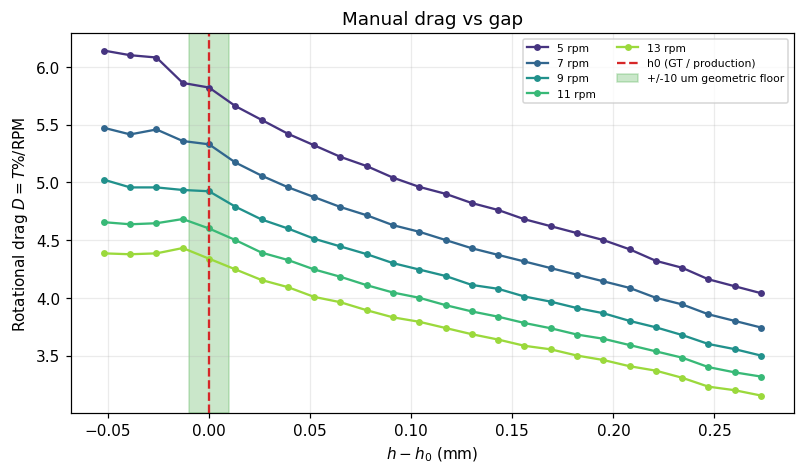

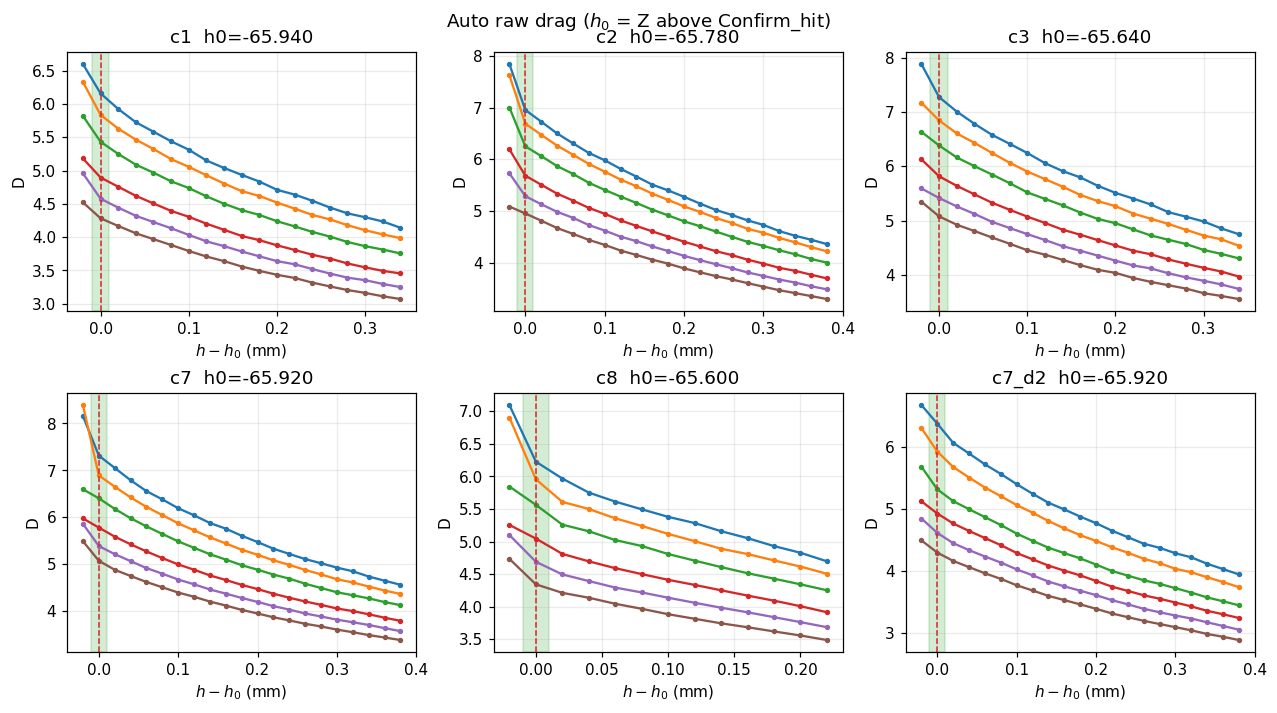

In [4]:
fig, ax = plt.subplots(figsize=(7.2, 4.2), constrained_layout=True)
rpms_m = sorted(manual["speed_RPM"].unique())
cmap = plt.cm.viridis(np.linspace(0.15, 0.85, len(rpms_m)))
for rpm, color in zip(rpms_m, cmap):
    sub = manual[manual["speed_RPM"] == rpm].sort_values("h_rel_mm")
    ax.plot(sub["h_rel_mm"], sub["drag"], "o-", ms=3.5, color=color, label=f"{int(rpm)} rpm")
ax.axvline(0.0, color="C3", ls="--", label="h0 (GT / production)")
ax.axvspan(-HIT_FLOOR_MM, HIT_FLOOR_MM, color="C2", alpha=0.25, label=f"+/-{HIT_FLOOR_MM*1e3:.0f} um geometric floor")
ax.set_xlabel(r"$h - h_0$ (mm)")
ax.set_ylabel(r"Rotational drag $D=T\%/\mathrm{RPM}$")
ax.set_title("Manual drag vs gap")
ax.legend(fontsize=7, ncol=2)
plt.show()

n_exp = len(exps)
n_cols = 3
n_rows = max(1, int(np.ceil(n_exp / n_cols)))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(11.5, 3.1 * n_rows), constrained_layout=True)
axes = np.atleast_1d(axes).ravel()
for ax, exp in zip(axes, exps):
    d = exp["df"]
    hz = hit_z_from_flags(d)
    for rpm, g in d.groupby("RPM"):
        g = g.sort_values("Z_Height_mm")
        drag = g["Rotational_Drag"] if "Rotational_Drag" in g else g["Torque_%"] / g["RPM"]
        ax.plot(g["Z_Height_mm"] - hz, drag, "o-", ms=2.5)
    ax.axvline(0.0, color="C3", ls="--", lw=1)
    ax.axvspan(-HIT_FLOOR_MM, HIT_FLOOR_MM, color="C2", alpha=0.2)
    ax.set_title(f"{exp['short']}  h0={hz:.3f}")
    ax.set_xlabel(r"$h-h_0$ (mm)")
    ax.set_ylabel("D")
for ax in axes[n_exp:]:
    ax.axis("off")
fig.suptitle(rf"Auto raw drag — all {n_exp} cells ($h_0$ = Z above Confirm_hit)", y=1.02)
plt.show()

## 4. Manual GT @ $h_0$ and geometric floor ($\pm 0.01\,\mathrm{mm}$)

**Fit:** Ostwald–de Waele $\tau=K\dot\gamma^{n}$ by log–OLS at $h_0$.

**Geometric floor (unavoidable standard).** Re-fit at $h_0\pm 0.01\,\mathrm{mm}$ on the manual curve. Those $|\Delta K|$ and $|\Delta n|$ are the best-case geometry-only error if hit is controlled to $\pm 0.01\,\mathrm{mm}$. No live fitter can beat this without better gap control.

Manual GT @ h0 (Inc 0): K=11.840, n=0.691, eta20=4699 cP, R2=0.99925


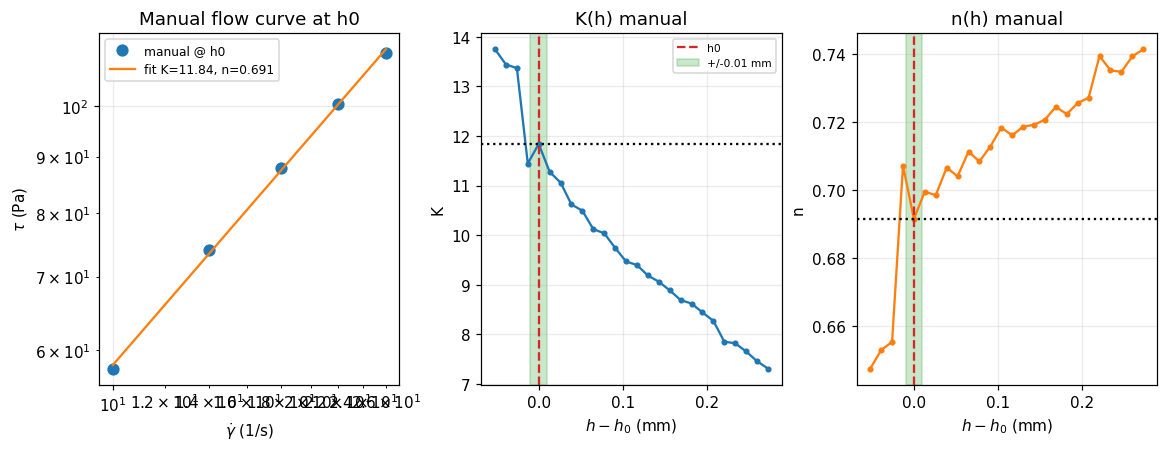

Geometric error budget (manual only; gap shifts +/-0.01 mm about h0):


,condition,h_rel_mm,K,n,dK_%,dn_%
0,h0 (GT),0.00,11.840,0.691,0.000,0.000
1,h0 - 0.01 mm (deep),-0.01,11.535,0.704,-2.582,1.754
2,h0 + 0.01 mm (shallow),0.01,11.408,0.698,-3.656,0.892


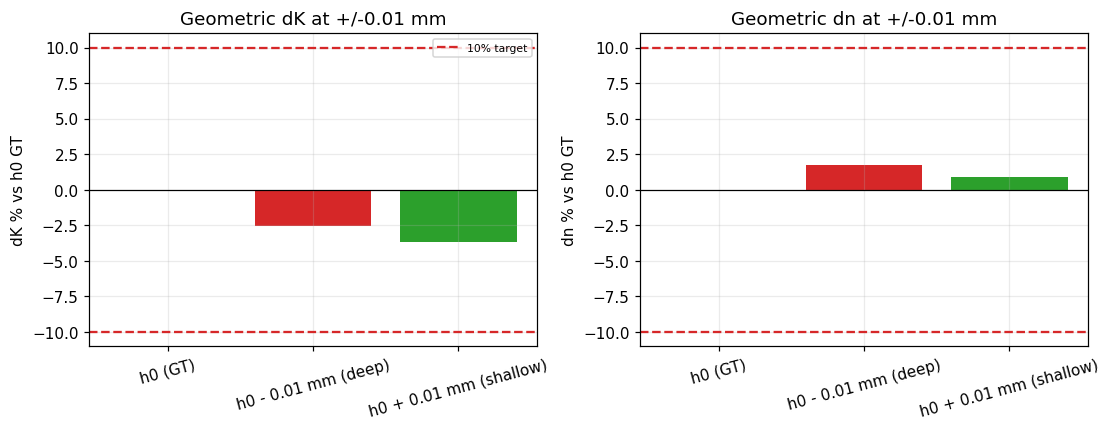


*** UNAVOIDABLE geometric floor (+/-10 um about h0) ***
  max |dK| = 3.66%
  max |dn| = 1.75%
  => 10% target is ABOVE this floor if hit is controlled to +/-0.01 mm.
  Live methods that leave residual >> floor are still geometry/hit limited.


In [5]:
def eta_app_cp(K, n, g=G_REF):
    return float(K * (g ** (n - 1.0)) * 1000.0)


def pct_err(pred, truth):
    return float(100.0 * (pred - truth) / truth)


def tau_gamma_at_h_rel(manual_df: pd.DataFrame, h_rel_mm: float) -> Tuple[np.ndarray, np.ndarray]:
    g_list, t_list = [], []
    for rpm, sub in manual_df.groupby("speed_RPM"):
        sub = sub.sort_values("h_rel_mm")
        if h_rel_mm < sub["h_rel_mm"].min() - 1e-9 or h_rel_mm > sub["h_rel_mm"].max() + 1e-9:
            continue
        tau = float(np.interp(h_rel_mm, sub["h_rel_mm"].to_numpy(), sub["tau_Pa"].to_numpy()))
        gamma = float(sub["gamma_dot_1_s"].iloc[0])
        if tau > 0 and gamma > 0:
            g_list.append(gamma)
            t_list.append(tau)
    return np.asarray(g_list), np.asarray(t_list)


inc_rows = []
for inc, g in manual.groupby("Increment"):
    pl = fit_stress_powerlaw(g["gamma_dot_1_s"], g["tau_Pa"])
    inc_rows.append({
        "Increment": int(inc),
        "h_rel_mm": float(inc) * MANUAL_INC_MM - H0_Z,
        "K": pl["K_stress"],
        "n": pl["n_stress"],
        "R2": pl["R2_stress"],
    })
inc_fit = pd.DataFrame(inc_rows).sort_values("h_rel_mm")

g_gt, t_gt = tau_gamma_at_h_rel(manual, 0.0)
pl_gt = fit_stress_powerlaw(g_gt, t_gt)
GT_K = float(pl_gt["K_stress"])
GT_n = float(pl_gt["n_stress"])
GT_ETA20 = eta_app_cp(GT_K, GT_n)
print(
    f"Manual GT @ h0 (Inc {H0_INC}): "
    f"K={GT_K:.3f}, n={GT_n:.3f}, eta20={GT_ETA20:.0f} cP, R2={pl_gt['R2_stress']:.5f}"
)

fig, axes = plt.subplots(1, 3, figsize=(10.5, 4.0), constrained_layout=True)
g_line = np.logspace(np.log10(g_gt.min()), np.log10(g_gt.max()), 50)
axes[0].loglog(g_gt, t_gt, "o", ms=7, label="manual @ h0")
axes[0].loglog(g_line, GT_K * g_line ** GT_n, "-", label=f"fit K={GT_K:.2f}, n={GT_n:.3f}")
axes[0].set_xlabel(r"$\dot\gamma$ (1/s)"); axes[0].set_ylabel(r"$\tau$ (Pa)")
axes[0].set_title("Manual flow curve at h0"); axes[0].legend(fontsize=8)

axes[1].plot(inc_fit["h_rel_mm"], inc_fit["K"], "o-", ms=3)
axes[1].axvline(0.0, color="C3", ls="--", label="h0")
axes[1].axvspan(-HIT_FLOOR_MM, HIT_FLOOR_MM, color="C2", alpha=0.25, label="+/-0.01 mm")
axes[1].axhline(GT_K, color="k", ls=":")
axes[1].set_xlabel(r"$h-h_0$ (mm)"); axes[1].set_ylabel("K"); axes[1].set_title("K(h) manual")
axes[1].legend(fontsize=7)

axes[2].plot(inc_fit["h_rel_mm"], inc_fit["n"], "o-", ms=3, color="C1")
axes[2].axvline(0.0, color="C3", ls="--")
axes[2].axvspan(-HIT_FLOOR_MM, HIT_FLOOR_MM, color="C2", alpha=0.25)
axes[2].axhline(GT_n, color="k", ls=":")
axes[2].set_xlabel(r"$h-h_0$ (mm)"); axes[2].set_ylabel("n"); axes[2].set_title("n(h) manual")
plt.show()

# --- Geometric floor: +/- 0.01 mm about h0 ---
geo_rows = []
for label, dh in [
    ("h0 (GT)", 0.0),
    ("h0 - 0.01 mm (deep)", -HIT_FLOOR_MM),
    ("h0 + 0.01 mm (shallow)", +HIT_FLOOR_MM),
]:
    g, t = tau_gamma_at_h_rel(manual, dh)
    pl = fit_stress_powerlaw(g, t)
    geo_rows.append({
        "condition": label,
        "h_rel_mm": dh,
        "K": pl["K_stress"],
        "n": pl["n_stress"],
        "dK_%": pct_err(pl["K_stress"], GT_K),
        "dn_%": pct_err(pl["n_stress"], GT_n),
    })
geo = pd.DataFrame(geo_rows)
GEO_K_FLOOR = float(geo.loc[geo["h_rel_mm"] != 0, "dK_%"].abs().max())
GEO_n_FLOOR = float(geo.loc[geo["h_rel_mm"] != 0, "dn_%"].abs().max())

print("Geometric error budget (manual only; gap shifts +/-0.01 mm about h0):")
display(geo.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10.0, 3.8), constrained_layout=True)
axes[0].bar(geo["condition"], geo["dK_%"], color=["C0", "C3", "C2"])
axes[0].axhline(0, color="k", lw=0.8)
axes[0].axhline(TARGET_PCT, color="C3", ls="--", label="10% target")
axes[0].axhline(-TARGET_PCT, color="C3", ls="--")
axes[0].set_ylabel("dK % vs h0 GT"); axes[0].set_title("Geometric dK at +/-0.01 mm")
axes[0].tick_params(axis="x", rotation=15); axes[0].legend(fontsize=7)

axes[1].bar(geo["condition"], geo["dn_%"], color=["C1", "C3", "C2"])
axes[1].axhline(0, color="k", lw=0.8)
axes[1].axhline(TARGET_PCT, color="C3", ls="--")
axes[1].axhline(-TARGET_PCT, color="C3", ls="--")
axes[1].set_ylabel("dn % vs h0 GT"); axes[1].set_title("Geometric dn at +/-0.01 mm")
axes[1].tick_params(axis="x", rotation=15)
plt.show()

print(
    f"\n*** UNAVOIDABLE geometric floor (+/-{HIT_FLOOR_MM*1e3:.0f} um about h0) ***\n"
    f"  max |dK| = {GEO_K_FLOOR:.2f}%\n"
    f"  max |dn| = {GEO_n_FLOOR:.2f}%\n"
    f"  => 10% target is ABOVE this floor if hit is controlled to +/-0.01 mm.\n"
    f"  Live methods that leave residual >> floor are still geometry/hit limited."
)

## 5. Production fits — one bar per cell

Live code today: `predict_cell_rheology` on **that cell only**, $\tau$ at $h_0$. No other cells involved.

Production @ h0 (standard):


,experiment,hit_z,pathway,n,K,eta20_cP,err_n_%,err_K_%
0,c1,-65.94,mild_shear_thinning,0.665,13.434,4922.972,-3.843,13.457
1,c2,-65.78,mild_shear_thinning,0.658,15.585,5595.647,-4.832,31.628
2,c3,-65.64,mild_shear_thinning,0.668,15.075,5577.416,-3.382,27.318
3,c7,-65.92,mild_shear_thinning,0.662,15.461,5616.366,-4.267,30.579
4,c8,-65.60,mild_shear_thinning,0.671,12.730,4752.418,-2.949,7.517
5,c7_d2,-65.92,mild_shear_thinning,0.658,14.172,5089.728,-4.817,19.692


Production: n CV=0.8% mean|err|=4.0% | K CV=8.1% mean|err|=21.7%


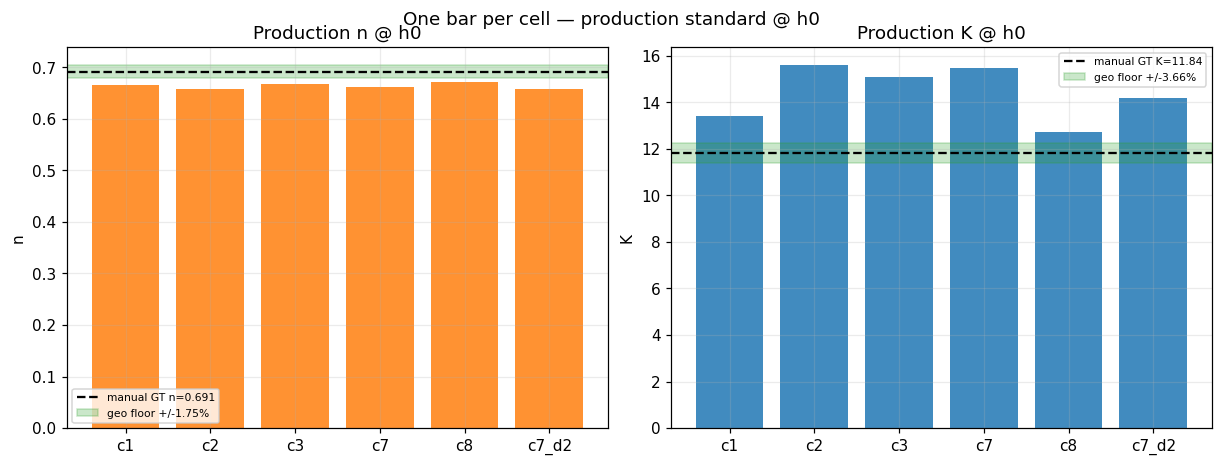

In [6]:
def points_from_exp(exp):
    d = exp["df"]
    cell = int(exp["cell"])
    hz = hit_z_from_flags(d)
    points = []
    for _, r in d.iterrows():
        rpm = float(r["RPM"])
        torque = float(r["Torque_%"])
        drag = float(r["Rotational_Drag"]) if pd.notna(r.get("Rotational_Drag")) else abs(torque) / rpm
        points.append({
            "cell_id": cell,
            "height": float(r["Z_Height_mm"]),
            "rpm": rpm,
            "torque_percent": torque,
            "rotational_drag": drag,
        })
    rpms = sorted({p["rpm"] for p in points})
    return points, hz, rpms


prod_rows = []
per_rpm_store: Dict[str, Any] = {}
for exp in exps:
    points, hz, rpms = points_from_exp(exp)
    per_rpm, summary = predict_cell_rheology(
        exp["cell"], rpms, points, torque_floor_pct=0.0, hit_point_z=hz
    )
    per_rpm_store[exp["name"]] = per_rpm
    K = summary.get("K_stress")
    n = summary.get("n_stress")
    if K is None or n is None or not (np.isfinite(K) and np.isfinite(n)):
        K = summary.get("K_Pas_n", np.nan)
        n = summary.get("n", np.nan)
    prod_rows.append({
        "experiment": exp["short"],
        "full_name": exp["name"],
        "hit_z": hz,
        "pathway": summary.get("pathway"),
        "n": float(n) if n is not None and np.isfinite(n) else np.nan,
        "K": float(K) if K is not None and np.isfinite(K) else np.nan,
        "eta20_cP": eta_app_cp(float(K), float(n)) if K is not None and n is not None and np.isfinite(K) and np.isfinite(n) else np.nan,
    })

prod = pd.DataFrame(prod_rows)
prod["err_K_%"] = prod["K"].apply(lambda v: pct_err(v, GT_K) if np.isfinite(v) else np.nan)
prod["err_n_%"] = prod["n"].apply(lambda v: pct_err(v, GT_n) if np.isfinite(v) else np.nan)

print("Production @ h0 (standard):")
display(prod[["experiment", "hit_z", "pathway", "n", "K", "eta20_cP", "err_n_%", "err_K_%"]].round(3))
print(
    f"Production: n CV={100*prod['n'].std()/prod['n'].mean():.1f}% mean|err|={prod['err_n_%'].abs().mean():.1f}% | "
    f"K CV={100*prod['K'].std()/prod['K'].mean():.1f}% mean|err|={prod['err_K_%'].abs().mean():.1f}%"
)

fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.0), constrained_layout=True)
x = np.arange(len(prod))
axes[0].bar(x, prod["n"], color="C1", alpha=0.85)
axes[0].axhline(GT_n, color="k", ls="--", label=f"manual GT n={GT_n:.3f}")
axes[0].axhspan(GT_n * (1 - GEO_n_FLOOR / 100), GT_n * (1 + GEO_n_FLOOR / 100),
                color="C2", alpha=0.25, label=f"geo floor +/-{GEO_n_FLOOR:.2f}%")
axes[0].set_xticks(x); axes[0].set_xticklabels(prod["experiment"], rotation=30, ha="right", fontsize=8)
axes[0].set_ylabel("n"); axes[0].set_title("Production n @ h0"); axes[0].legend(fontsize=7)

axes[1].bar(x, prod["K"], color="C0", alpha=0.85)
axes[1].axhline(GT_K, color="k", ls="--", label=f"manual GT K={GT_K:.2f}")
axes[1].axhspan(GT_K * (1 - GEO_K_FLOOR / 100), GT_K * (1 + GEO_K_FLOOR / 100),
                color="C2", alpha=0.25, label=f"geo floor +/-{GEO_K_FLOOR:.2f}%")
axes[1].set_xticks(x); axes[1].set_xticklabels(prod["experiment"], rotation=30, ha="right", fontsize=8)
axes[1].set_ylabel("K"); axes[1].set_title("Production K @ h0"); axes[1].legend(fontsize=7)
fig.suptitle(f"One bar per cell (n={len(prod)}) — production standard @ h0", y=1.02)
plt.show()

## 6. Live per-cell candidates (toward $<10\%$)

Each method runs on **one cell's** gap×RPM sweep only. Errors are vs manual GT @ $h_0$. Horizontal references: **10% target** and **geometric floor**.

| Candidate | Live change | Idea |
|---|---|---|
| **A. Production @ $h_0$** | (baseline) | Current `predict_cell_rheology` |
| **B. Fixed-offset $\tau$** | After hit, read $\tau$ at $h_0+\delta$ (20–100 µm), log-OLS | Corrects systematic over-deep hit |
| **C. NLS on $\tau(h_0)$** | Same hit stresses, nonlinear LS | Fitter change only |
| **D. Hyperbola @ $h_{\mathrm{norm}}=\delta$** | Evaluate fitted $D=A/(h+h_c)+B$ at shallow $\delta$, then log-OLS | Model-based gap offset without re-interp |

Offset methods change **which gap** is used (protocol). They do not beat geometry if the labeled $h_0$ is wrong by more than the floor.

Per-cell LIVE methods only (stats over 6 independent cells vs GT @ h0):


,method,n_mean,n_std,K_mean,K_std,abs_err_n,abs_err_K,n_cells
1,B: offset +100um logOLS,0.686,0.006,11.602,0.848,1.085,6.119,6
8,D: hyperbola @ +60um,0.678,0.006,12.442,0.934,1.951,7.575,6
4,B: offset +60um logOLS,0.680,0.007,12.412,0.973,1.688,7.671,6
3,B: offset +40um logOLS,0.675,0.008,12.909,1.062,2.323,10.391,6
7,D: hyperbola @ +40um,0.674,0.006,13.013,1.001,2.599,10.620,6
2,B: offset +20um logOLS,0.669,0.007,13.530,1.125,3.281,14.266,6
6,D: hyperbola @ +20um,0.669,0.006,13.663,1.076,3.286,15.394,6
0,A: production @ h0,0.664,0.005,14.410,1.163,4.015,21.699,6
5,C: NLS on tau_hit,0.658,0.005,14.645,1.144,4.837,23.683,6



Methods with mean |err| < 10% on BOTH n and K:


,method,abs_err_n,abs_err_K,n_cells
1,B: offset +100um logOLS,1.085,6.119,6
8,D: hyperbola @ +60um,1.951,7.575,6
4,B: offset +60um logOLS,1.688,7.671,6


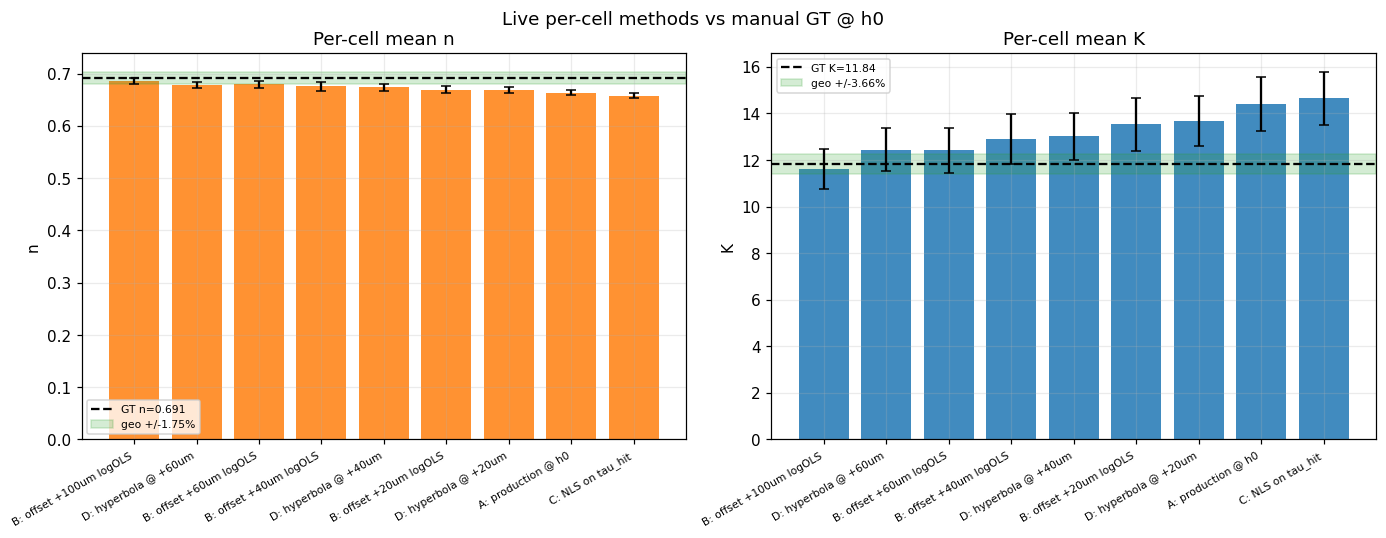

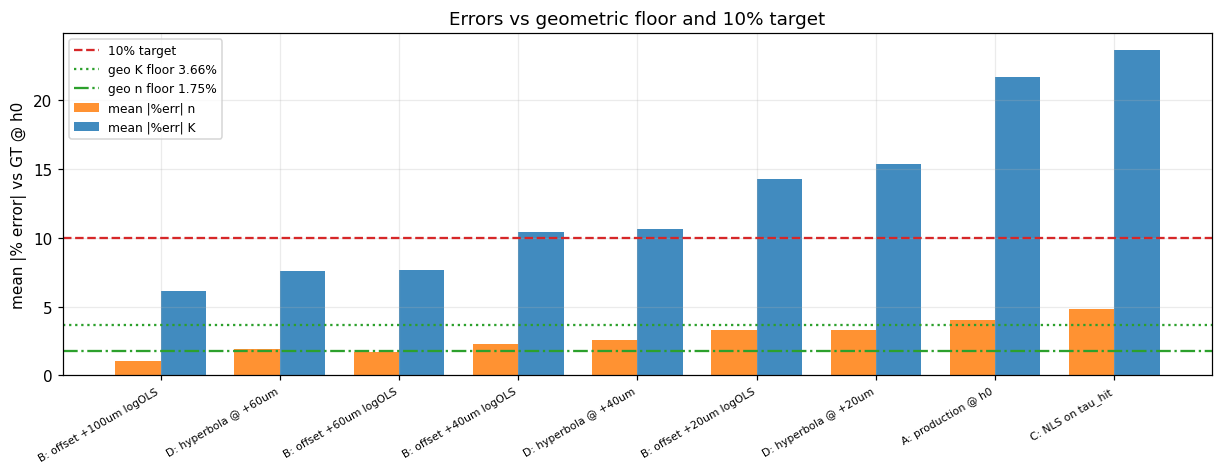


Reminder: geometric floor is from manual h0+/-0.01 mm. Improving the tau-gamma fitter without fixing hit depth cannot beat that floor.


In [7]:
def tau_at_offset(exp, offset_mm: float) -> Tuple[np.ndarray, np.ndarray]:
    points, hz, rpms = points_from_exp(exp)
    target = hz + offset_mm  # shallower when offset>0
    g, taus = [], []
    for rpm in rpms:
        pts = filter_measurement_points(points, exp["cell"], float(rpm))
        if len(pts) < 2:
            continue
        zs = np.array([p["height"] for p in pts], float)
        ts = np.array([p["torque_percent"] for p in pts], float)
        o = np.argsort(zs)
        zs, ts = zs[o], ts[o]
        if target < zs.min() - 1e-9 or target > zs.max() + 1e-9:
            continue
        t_use = float(np.interp(target, zs, ts))
        if t_use <= 0:
            continue
        g.append(float(shear_rate(rpm)))
        taus.append(PCT_TO_PA * t_use)
    return np.asarray(g), np.asarray(taus)


def tau_from_hyperbola_at_hnorm(per_rpm: Dict[float, Dict[str, Any]], h_norm_mm: float):
    # D(h) = A/(h + hc) + B evaluated at h_norm; torque = D * RPM.
    g, taus = [], []
    for rpm, fit in per_rpm.items():
        if not fit.get("success"):
            continue
        A, B, hc = fit.get("A"), fit.get("B"), fit.get("hc")
        if A is None or B is None or hc is None:
            continue
        if not (np.isfinite(A) and np.isfinite(B) and np.isfinite(hc) and hc > 0):
            continue
        drag = float(A) / (float(h_norm_mm) + float(hc)) + float(B)
        if not np.isfinite(drag) or drag <= 0:
            continue
        torque = drag * float(rpm)
        g.append(float(shear_rate(rpm)))
        taus.append(PCT_TO_PA * torque)
    return np.asarray(g), np.asarray(taus)


def nls_Kn(g, t):
    g = np.asarray(g, float); t = np.asarray(t, float)
    m = np.isfinite(g) & np.isfinite(t) & (g > 0) & (t > 0)
    g, t = g[m], t[m]
    if len(g) < 2:
        return {"K": np.nan, "n": np.nan}
    seed = fit_stress_powerlaw(g, t)
    def model(x, K, n):
        return K * np.power(x, n)
    popt, _ = curve_fit(
        model, g, t,
        p0=[seed["K_stress"], seed["n_stress"]],
        bounds=([1e-6, 0.05], [1e3, 1.5]),
        maxfev=20000,
    )
    return {"K": float(popt[0]), "n": float(popt[1])}


OFFSETS_MM = [0.02, 0.04, 0.06, 0.10]
HYPER_DELTAS = [0.02, 0.04, 0.06]

live_rows = []
for exp, prow in zip(exps, prod.itertuples(index=False)):
    # A) production
    live_rows.append({
        "experiment": exp["short"], "method": "A: production @ h0",
        "K": prow.K, "n": prow.n,
    })
    # C) NLS on production hit stresses
    g_hit, t_hit = [], []
    for rpm, fit in per_rpm_store[exp["name"]].items():
        if fit.get("success") and fit.get("tau_Pa_hit"):
            g_hit.append(float(shear_rate(rpm)))
            t_hit.append(float(fit["tau_Pa_hit"]))
    nls = nls_Kn(g_hit, t_hit)
    live_rows.append({
        "experiment": exp["short"], "method": "C: NLS on tau_hit",
        "K": nls["K"], "n": nls["n"],
    })
    # B) fixed-offset interpolated tau
    for off in OFFSETS_MM:
        g, t = tau_at_offset(exp, off)
        if len(g) < 2:
            continue
        pl = fit_stress_powerlaw(g, t)
        live_rows.append({
            "experiment": exp["short"],
            "method": f"B: offset +{off*1e3:.0f}um logOLS",
            "K": pl["K_stress"], "n": pl["n_stress"],
        })
    # D) hyperbola evaluated at h_norm = +delta
    for dh in HYPER_DELTAS:
        g, t = tau_from_hyperbola_at_hnorm(per_rpm_store[exp["name"]], dh)
        if len(g) < 2:
            continue
        pl = fit_stress_powerlaw(g, t)
        live_rows.append({
            "experiment": exp["short"],
            "method": f"D: hyperbola @ +{dh*1e3:.0f}um",
            "K": pl["K_stress"], "n": pl["n_stress"],
        })

live = pd.DataFrame(live_rows)
live["err_K_%"] = live["K"].apply(lambda v: pct_err(v, GT_K) if np.isfinite(v) else np.nan)
live["err_n_%"] = live["n"].apply(lambda v: pct_err(v, GT_n) if np.isfinite(v) else np.nan)

summary = (
    live.groupby("method")
    .agg(
        n_mean=("n", "mean"), n_std=("n", "std"),
        K_mean=("K", "mean"), K_std=("K", "std"),
        abs_err_n=("err_n_%", lambda s: float(np.nanmean(np.abs(s)))),
        abs_err_K=("err_K_%", lambda s: float(np.nanmean(np.abs(s)))),
        n_cells=("experiment", "nunique"),
    )
    .reset_index()
    .sort_values("abs_err_K")
)

print(f"Per-cell LIVE methods only (stats over {len(exps)} independent cells vs GT @ h0):")
display(summary.round(3))

# mark which clear 10% on BOTH
summary["under_10_both"] = (summary["abs_err_n"] < TARGET_PCT) & (summary["abs_err_K"] < TARGET_PCT)
print("\nMethods with mean |err| < 10% on BOTH n and K:")
display(summary.loc[summary["under_10_both"], ["method", "abs_err_n", "abs_err_K", "n_cells"]].round(3))
if not summary["under_10_both"].any():
    print("  (none yet — best by K error listed first above)")

order = summary["method"].tolist()
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), constrained_layout=True)
x = np.arange(len(summary))
axes[0].bar(x, summary["n_mean"], yerr=summary["n_std"].fillna(0), color="C1", alpha=0.85, capsize=3)
axes[0].axhline(GT_n, color="k", ls="--", label=f"GT n={GT_n:.3f}")
axes[0].axhspan(GT_n * (1 - GEO_n_FLOOR / 100), GT_n * (1 + GEO_n_FLOOR / 100),
                color="C2", alpha=0.2, label=f"geo +/-{GEO_n_FLOOR:.2f}%")
axes[0].set_xticks(x); axes[0].set_xticklabels(summary["method"], rotation=30, ha="right", fontsize=7)
axes[0].set_ylabel("n"); axes[0].set_title("Per-cell mean n"); axes[0].legend(fontsize=7)

axes[1].bar(x, summary["K_mean"], yerr=summary["K_std"].fillna(0), color="C0", alpha=0.85, capsize=3)
axes[1].axhline(GT_K, color="k", ls="--", label=f"GT K={GT_K:.2f}")
axes[1].axhspan(GT_K * (1 - GEO_K_FLOOR / 100), GT_K * (1 + GEO_K_FLOOR / 100),
                color="C2", alpha=0.2, label=f"geo +/-{GEO_K_FLOOR:.2f}%")
axes[1].set_xticks(x); axes[1].set_xticklabels(summary["method"], rotation=30, ha="right", fontsize=7)
axes[1].set_ylabel("K"); axes[1].set_title("Per-cell mean K"); axes[1].legend(fontsize=7)
fig.suptitle("Live per-cell methods vs manual GT @ h0", y=1.03)
plt.show()

fig, ax = plt.subplots(figsize=(11.0, 4.2), constrained_layout=True)
w = 0.38
ax.bar(x - w / 2, summary["abs_err_n"], width=w, color="C1", alpha=0.85, label="mean |%err| n")
ax.bar(x + w / 2, summary["abs_err_K"], width=w, color="C0", alpha=0.85, label="mean |%err| K")
ax.axhline(TARGET_PCT, color="C3", ls="--", label="10% target")
ax.axhline(GEO_K_FLOOR, color="C2", ls=":", label=f"geo K floor {GEO_K_FLOOR:.2f}%")
ax.axhline(GEO_n_FLOOR, color="C2", ls="-.", label=f"geo n floor {GEO_n_FLOOR:.2f}%")
ax.set_xticks(x); ax.set_xticklabels(summary["method"], rotation=30, ha="right", fontsize=7)
ax.set_ylabel("mean |% error| vs GT @ h0")
ax.set_title("Errors vs geometric floor and 10% target")
ax.legend(fontsize=8)
plt.show()

print(
    "\nReminder: geometric floor is from manual h0+/-0.01 mm. "
    "Improving the tau-gamma fitter without fixing hit depth cannot beat that floor."
)

## 7. What to implement next

**Standard locked.** GT and production both at detected $h_0$. Geometric floor = manual $|\Delta K|$, $|\Delta n|$ at $h_0\pm 0.01\,\mathrm{mm}$.

**Honest constraint.** If production $|{\rm err}|$ on $K$ is tens of percent while the geometric floor is only a few percent, the effective hit/gap error on auto is **larger than 0.01 mm** (or there is a torque-scale bias). Curve-fit tweaks at the same bad gap will not close that gap.

**Live search direction (still per-cell):**

1. Keep reporting production @ $h_0$ as the primary number.
2. Optionally evaluate a fixed shallow offset (Candidate B/D) as a **diagnostic / secondary** protocol if hit bias remains.
3. Tighten hit detection / Z metrology toward the $\pm 0.01\,\mathrm{mm}$ floor — that is what makes $<10\%$ on $K$ realistic.